# Telco Customer Churn: Exploratory Analysis

**Goal:** find which customer attributes are most related to churn, to decide what to show in the Power BI dashboard and which signals to use in the SQL risk score.

**Data:** `Data/telco_churn_raw.csv`: 7,043 customers of a telecom provider (IBM Telco sample dataset), 21 columns.

**Contents**
1. Load and clean the data
2. Numerical features: correlation with churn
3. Tenure: when do customers churn?
4. Charges: do churners pay more?
5. Categorical features: Cramér's V
6. Insights

## 1. Load and clean the data

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid')

# Consistent colours across all charts: retained = blue, churned = orange
CHURN_COLORS = {0: '#257de0', 1: '#f47230'}
CHURN_LABELS = {0: 'Retained', 1: 'Churned'}

DATA_DIR = Path('..') / 'Data'   # paths are relative to this notebook's folder
raw = pd.read_csv(DATA_DIR / 'telco_churn_raw.csv')
df = raw.copy()
df.head(3)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

`TotalCharges` is stored as text because 11 rows contain a blank. Converting it to numbers shows that all 11 are customers with `tenure = 0`: brand-new accounts that have not been billed yet and cannot have churned. They are removed rather than filled with 0, which would pull down the averages. This matches the cleaned dataset used in SQL and Power BI (7,032 customers).

In [3]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df.loc[df['TotalCharges'].isna(), ['customerID', 'tenure', 'TotalCharges', 'Churn']]

,customerID,tenure,TotalCharges,Churn
488,4472-LVYGI,0,NaN,No
753,3115-CZMZD,0,NaN,No
936,5709-LVOEQ,0,NaN,No
1082,4367-NUYAO,0,NaN,No
1340,1371-DWPAZ,0,NaN,No
3331,7644-OMVMY,0,NaN,No
3826,3213-VVOLG,0,NaN,No
4380,2520-SGTTA,0,NaN,No
5218,2923-ARZLG,0,NaN,No
6670,4075-WKNIU,0,NaN,No


In [4]:
df = df[df['tenure'] > 0].reset_index(drop=True)

# Numeric churn flag (1 = churned) so churn rate = mean
df['churns'] = df['Churn'].map({'Yes': 1, 'No': 0})

print(f"Customers: {len(df):,}")
print(f"Missing values: {df.isna().sum().sum()}")
print(f"Overall churn rate: {df['churns'].mean():.2%}")

Customers: 7,032
Missing values: 0
Overall churn rate: 26.58%

## 2. Numerical features: correlation with churn

In [5]:
num_cols = ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'churns']
corr = df[num_cols].corr()
corr.round(3)

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,churns
SeniorCitizen,1.000,0.016,0.220,0.102,0.151
tenure,0.016,1.000,0.247,0.826,-0.354
MonthlyCharges,0.220,0.247,1.000,0.651,0.193
TotalCharges,0.102,0.826,0.651,1.000,-0.199
churns,0.151,-0.354,0.193,-0.199,1.000


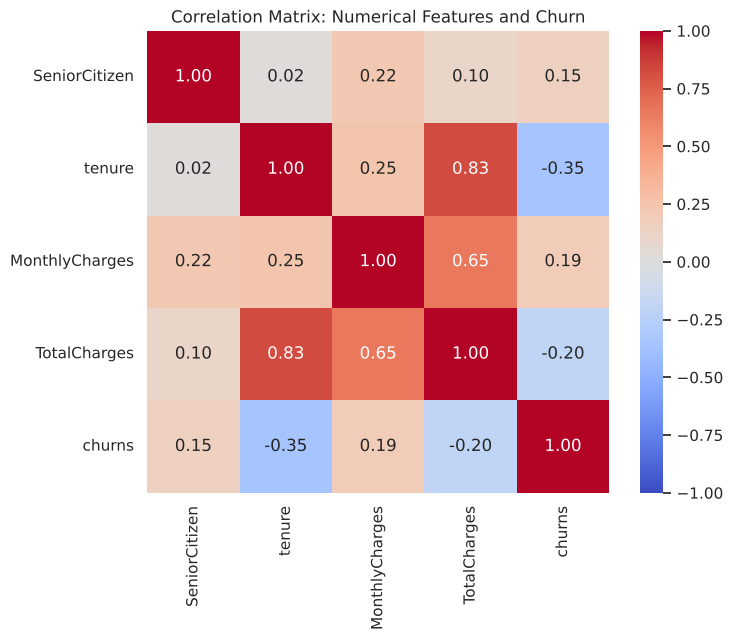

In [6]:
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, center=0, square=True)
plt.title('Correlation Matrix: Numerical Features and Churn')
plt.show()

- **Tenure** has the strongest relationship with churn (r = -0.35): long-standing customers rarely leave.
- **MonthlyCharges** is positively related (r = 0.19): higher bills, slightly more churn.
- **TotalCharges** is negative (r = -0.20) only because it is mostly driven by tenure (r = 0.83 between them).

## 3. Tenure: when do customers churn?

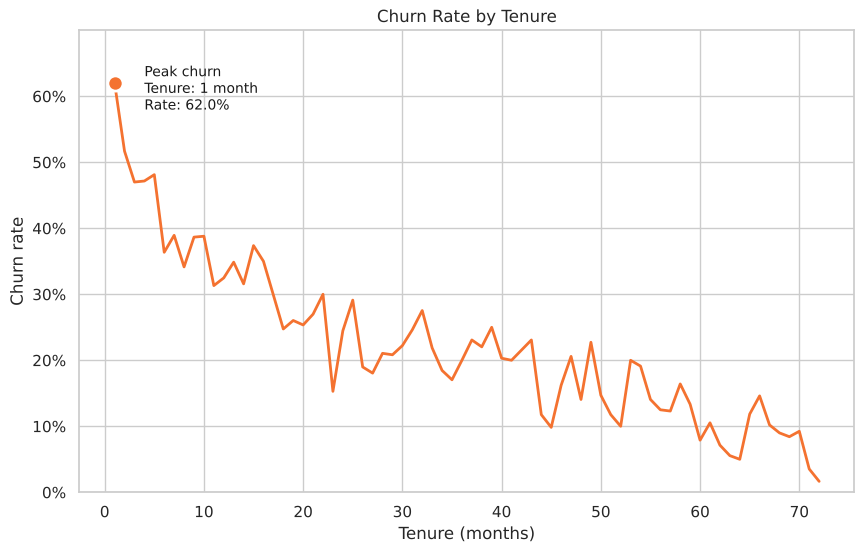

In [7]:
churn_by_tenure = df.groupby('tenure')['churns'].mean()
peak_x, peak_y = churn_by_tenure.idxmax(), churn_by_tenure.max()

plt.figure(figsize=(10, 6))
sns.lineplot(x=churn_by_tenure.index, y=churn_by_tenure.values, color=CHURN_COLORS[1], linewidth=2)
plt.scatter(peak_x, peak_y, color=CHURN_COLORS[1], s=120, zorder=5, edgecolor='white', linewidth=2)
plt.annotate(f"Peak churn\nTenure: {peak_x} month\nRate: {peak_y:.1%}",
             xy=(peak_x, peak_y), xytext=(peak_x + 3, peak_y - 0.04), fontsize=10, color='#191919')
plt.title('Churn Rate by Tenure')
plt.xlabel('Tenure (months)')
plt.ylabel('Churn rate')
plt.gca().yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
plt.ylim(0, peak_y + 0.08)
plt.show()

In [8]:
df['tenure_group'] = pd.cut(df['tenure'], bins=[0, 6, 12, 24, np.inf],
                            labels=['0-6 months', '7-12 months', '13-24 months', '25+ months'])
tenure_summary = df.groupby('tenure_group', observed=True)['churns'].agg(churn_rate='mean', customers='size')
tenure_summary['churn_rate'] = (tenure_summary['churn_rate'] * 100).round(2)
tenure_summary

,churn_rate,customers
tenure_group,,
0-6 months,53.33,1470
7-12 months,35.89,705
13-24 months,28.71,1024
25+ months,14.04,3833


In [9]:
df.groupby('churns')['tenure'].mean().round(2).rename(index=CHURN_LABELS)

churns
Retained    37.65
Churned     17.98
Name: tenure, dtype: float64

## 4. Charges: do churners pay more?

In [10]:
charges = df.groupby('churns')[['MonthlyCharges', 'TotalCharges']].mean().round(2).rename(index=CHURN_LABELS)
charges

,MonthlyCharges,TotalCharges
churns,,
Retained,61.31,2555.34
Churned,74.44,1531.80


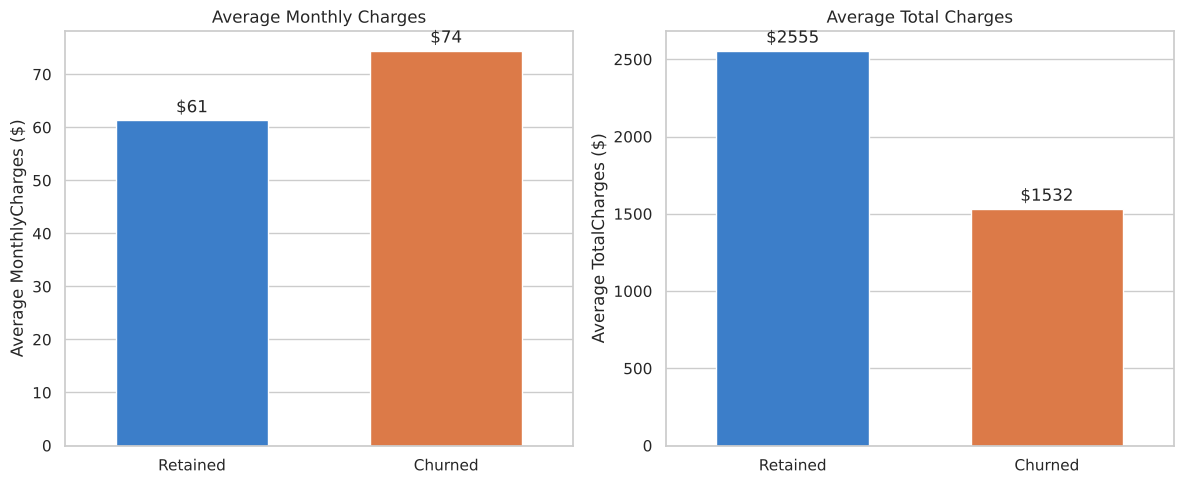

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, col in zip(axes, ['MonthlyCharges', 'TotalCharges']):
    sns.barplot(data=df, x='churns', y=col, estimator='mean', errorbar=None,
                hue='churns', palette=CHURN_COLORS, legend=False, ax=ax, width=0.6)
    ax.set_xticks([0, 1], [CHURN_LABELS[0], CHURN_LABELS[1]])
    ax.set_xlabel('')
    ax.set_ylabel(f'Average {col} ($)')
    for container in ax.containers:
        ax.bar_label(container, fmt='$%.0f', padding=3)
axes[0].set_title('Average Monthly Charges')
axes[1].set_title('Average Total Charges')
plt.tight_layout()
plt.show()

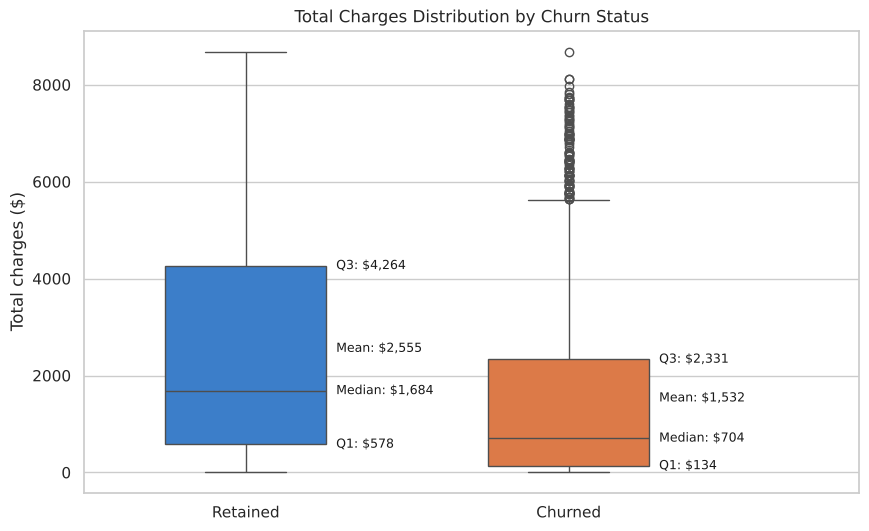

In [12]:
plt.figure(figsize=(10, 6))
ax = sns.boxplot(data=df, x='churns', y='TotalCharges', hue='churns', palette=CHURN_COLORS, legend=False, width=0.5)
ax.set_xticks([0, 1], [CHURN_LABELS[0], CHURN_LABELS[1]])

# Annotate quartiles and mean of TotalCharges for each group
charge_stats = df.groupby('churns')['TotalCharges'].describe()
for i, churn_value in enumerate(charge_stats.index):
    s = charge_stats.loc[churn_value]
    for label, key in [('Q1', '25%'), ('Median', '50%'), ('Mean', 'mean'), ('Q3', '75%')]:
        ax.text(i + 0.28, s[key], f"{label}: ${s[key]:,.0f}", va='center', fontsize=9, color='#191919')

plt.title('Total Charges Distribution by Churn Status')
plt.xlabel('')
plt.ylabel('Total charges ($)')
plt.xlim(-0.5, 1.9)
plt.show()

Churners pay **more per month** (\$74 vs \$61) but bring in **less total revenue** (\$1,532 vs \$2,555) because they leave early. Short tenure, not price alone, is what destroys customer value.

## 5. Categorical features: Cramér's V

Cramér's V measures the strength of association between two categorical variables (0 = none, 1 = perfect). The bias-corrected version (Bergsma, 2013) is used so that columns with more categories are not favoured.

In [13]:
def cramers_v(x, y):
    """Bias-corrected Cramér's V between two categorical series."""
    table = pd.crosstab(x, y)
    chi2 = chi2_contingency(table, correction=False)[0]
    n = table.to_numpy().sum()
    r, k = table.shape
    phi2 = chi2 / n
    phi2_corr = max(0, phi2 - (k - 1) * (r - 1) / (n - 1))
    r_corr = r - (r - 1) ** 2 / (n - 1)
    k_corr = k - (k - 1) ** 2 / (n - 1)
    return np.sqrt(phi2_corr / min(k_corr - 1, r_corr - 1))

In [14]:
# Customer and service attributes (customerID and the text Churn column are excluded)
cat_cols = [
    'gender', 'SeniorCitizen', 'Partner', 'Dependents',
    'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
    'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
    'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod'
]

scores = (pd.Series({col: cramers_v(df[col], df['churns']) for col in cat_cols}, name="cramers_v")
            .sort_values(ascending=False))
scores.round(3).to_frame()

,cramers_v
Contract,0.409
OnlineSecurity,0.347
TechSupport,0.342
InternetService,0.321
PaymentMethod,0.302
OnlineBackup,0.291
DeviceProtection,0.281
StreamingMovies,0.230
StreamingTV,0.230
PaperlessBilling,0.191


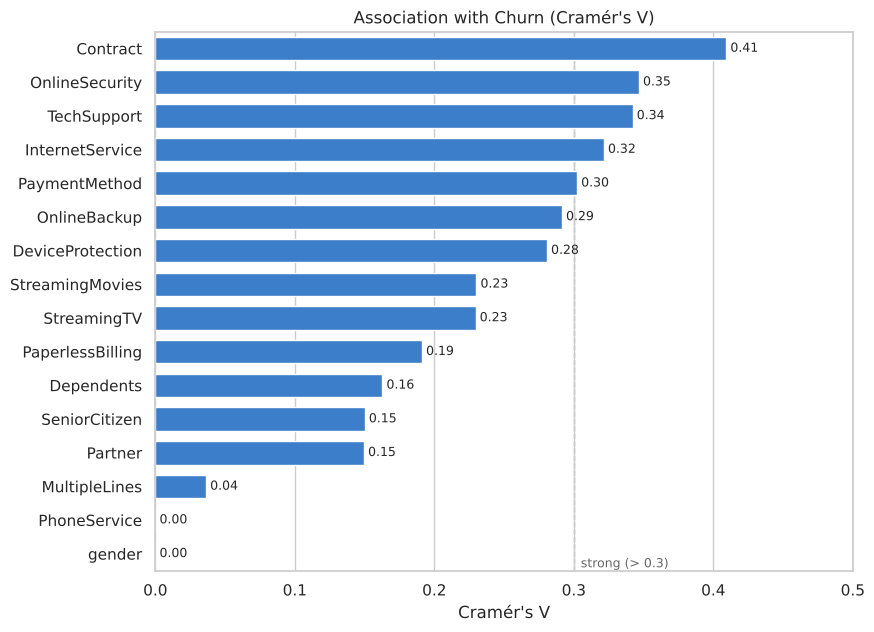

In [15]:
plt.figure(figsize=(9, 7))
ax = sns.barplot(x=scores.values, y=scores.index, color=CHURN_COLORS[0], width=0.7)
ax.bar_label(ax.containers[0], fmt='%.2f', padding=3, fontsize=9)
ax.axvline(0.3, color='#999999', linestyle='--', linewidth=1, zorder=0)
ax.text(0.305, len(scores) - 0.6, 'strong (> 0.3)', color='#666666', fontsize=9)
plt.title("Association with Churn (Cramér's V)")
plt.xlabel("Cramér's V")
plt.ylabel('')
plt.xlim(0, 0.5)
plt.show()

In [16]:
# Churn rate within each category of the strongest features
for col in scores.index[:6]:
    rates = (df.groupby(col)['churns'].agg(churn_rate='mean', customers='size')
               .assign(churn_rate=lambda t: (t['churn_rate'] * 100).round(2))
               .sort_values('churn_rate', ascending=False))
    print(f"{col}  (Cramér's V = {scores[col]:.3f})")
    print(rates.to_string(), end='\n\n')

Contract  (Cramér's V = 0.409)
                churn_rate  customers
Contract                             
Month-to-month       42.71       3875
One year             11.28       1472
Two year              2.85       1685

OnlineSecurity  (Cramér's V = 0.347)
                     churn_rate  customers
OnlineSecurity                            
No                        41.78       3497
Yes                       14.64       2015
No internet service        7.43       1520

TechSupport  (Cramér's V = 0.342)
                     churn_rate  customers
TechSupport                               
No                        41.65       3472
Yes                       15.20       2040
No internet service        7.43       1520

InternetService  (Cramér's V = 0.321)
                 churn_rate  customers
InternetService                       
Fiber optic           41.89       3096
DSL                   19.00       2416
No                     7.43       1520

PaymentMethod  (Cramér's V = 0.302)
     

In [17]:
for col in ['PaperlessBilling', 'SeniorCitizen', 'PhoneService', 'MultipleLines', 'gender']:
    rates = (df.groupby(col)['churns'].mean() * 100).round(2)
    print(f"{col:<17} V = {scores[col]:.3f}   churn rate % -> {rates.to_dict()}")

PaperlessBilling  V = 0.191   churn rate % -> {'No': 16.38, 'Yes': 33.59}
SeniorCitizen     V = 0.150   churn rate % -> {0: 23.65, 1: 41.68}
PhoneService      V = 0.000   churn rate % -> {'No': 25.0, 'Yes': 26.75}
MultipleLines     V = 0.036   churn rate % -> {'No': 25.08, 'No phone service': 25.0, 'Yes': 28.65}
gender            V = 0.000   churn rate % -> {'Female': 26.96, 'Male': 26.2}

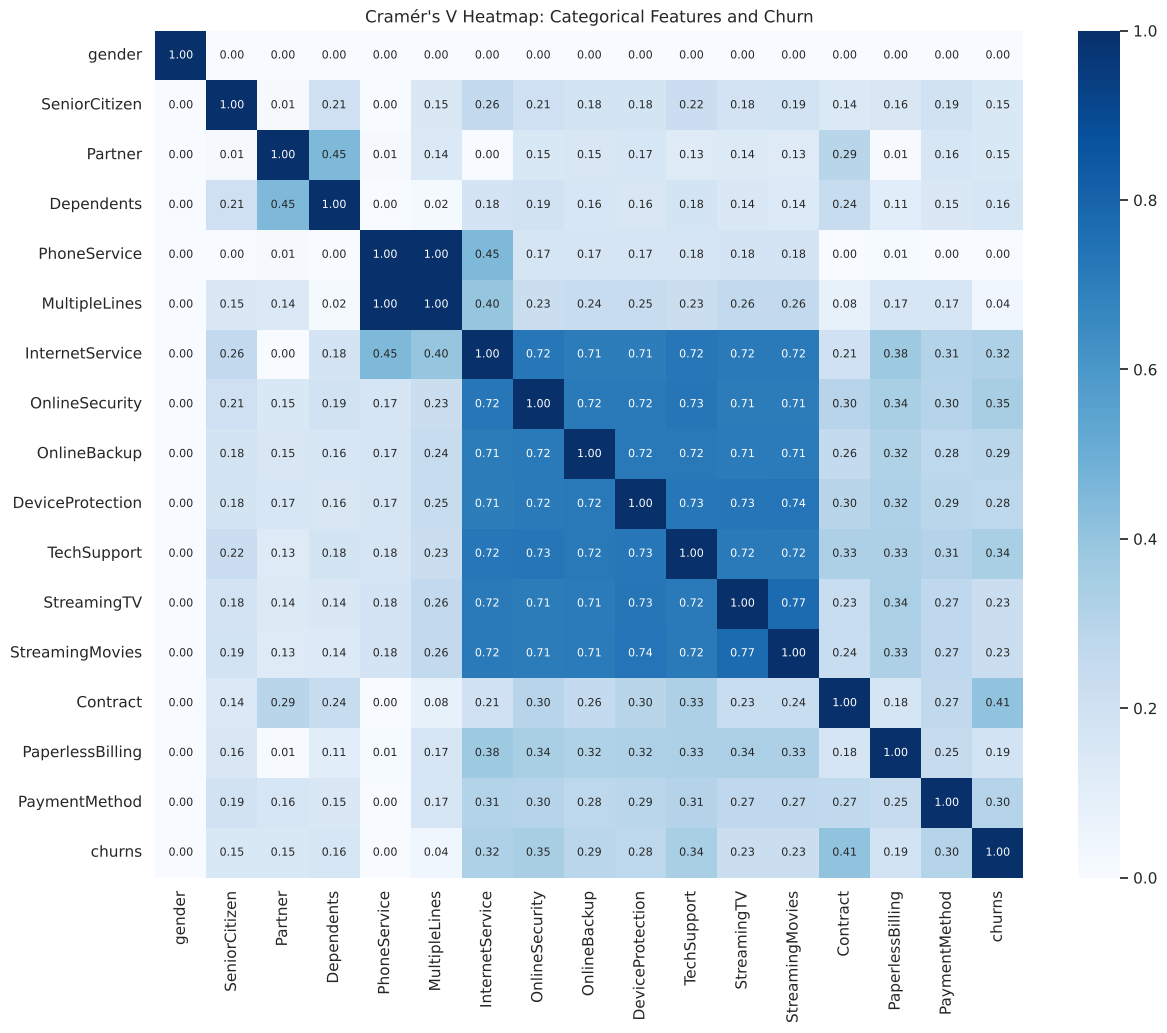

In [18]:
cols = cat_cols + ['churns']
matrix = pd.DataFrame(
    [[cramers_v(df[c1], df[c2]) for c2 in cols] for c1 in cols],
    index=cols, columns=cols
)

plt.figure(figsize=(14, 11))
sns.heatmap(matrix, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1, annot_kws={'size': 8})
plt.title("Cramér's V Heatmap: Categorical Features and Churn")
plt.show()

The heatmap also shows strong associations **between** features. Online security, backup, device protection, tech support and streaming are all strongly linked to `InternetService`, because customers without internet cannot have them (the `"No internet service"` category). These features overlap, which is why the risk score uses only a few of them.

## 6. Insights

| # | Finding | Evidence |
|---|---------|----------|
| 1 | **Contract type is the strongest churn driver.** Month-to-month customers churn at 42.7% vs 11.3% (one year) and 2.8% (two year). | V = 0.41 |
| 2 | **Lack of online security and tech support** strongly predicts churn: 41.8% / 41.6% churn without them vs 14.6% / 15.2% with them. | V = 0.35 / 0.34 |
| 3 | **Fiber optic** customers churn at 41.9%, more than twice DSL (19.0%); customers without internet churn at 7.4%. | V = 0.32 |
| 4 | **Electronic check** payers churn at 45.3%, the highest of all payment methods (others: 15-19%). | V = 0.30 |
| 5 | **Churn is concentrated early:** 53.3% of customers in their first 6 months churn vs 14.0% after 2 years. Churners stay 18 months on average vs 38 for retained customers. | r = -0.35 |
| 6 | **Churners pay more per month** (\$74 vs \$61) but generate less lifetime revenue (\$1,532 vs \$2,555). | means |
| 7 | **Moderate effects:** online backup, device protection, streaming, paperless billing (33.6% vs 16.4%), senior citizens (41.7% vs 23.6%), and customers without a partner or dependents. | V = 0.15-0.29 |
| 8 | **No meaningful effect:** gender, phone service and multiple lines. | V < 0.04 |

**Used downstream:** contract, internet service, payment method, tech support, online security and tenure were chosen as the six risk-score signals in SQL and as the main dashboard visuals.